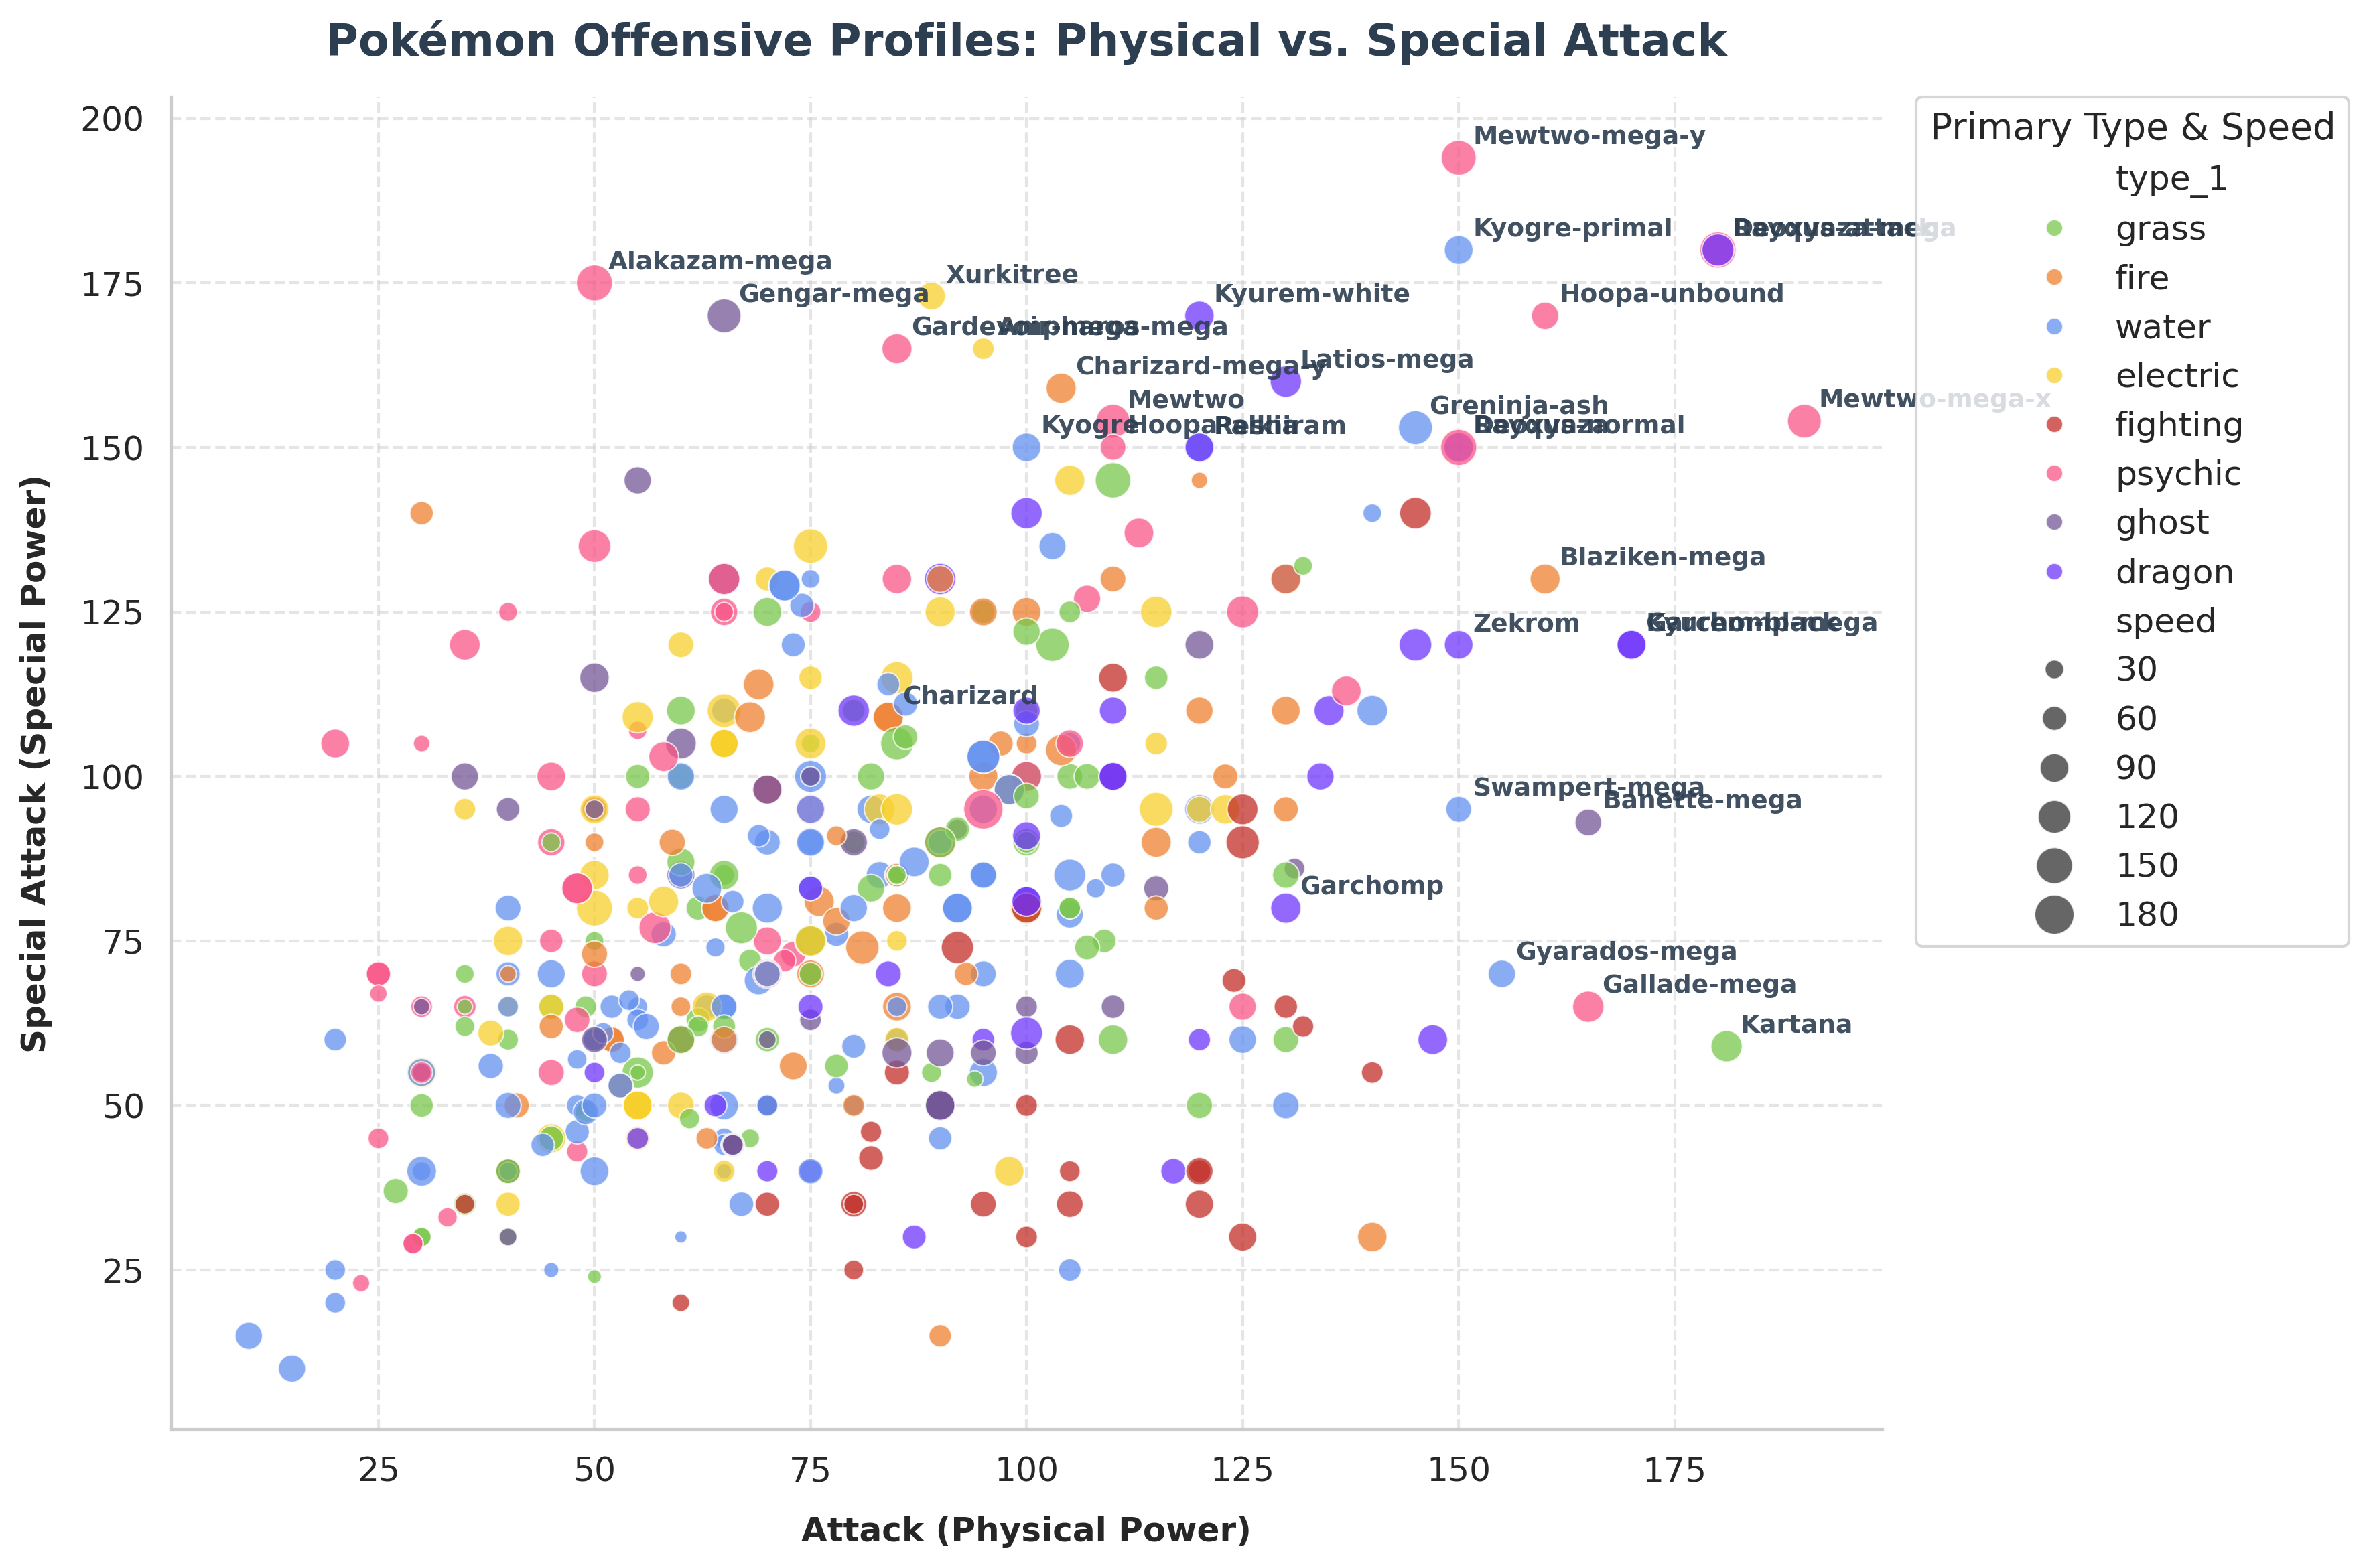

In [1]:
# Install required libraries if you don't have them:
# pip install pandas seaborn matplotlib numpy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Load data directly from the TidyTuesday GitHub repository
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-04-01/pokemon_df.csv"
pokemon_df = pd.read_csv(url)

# Clean/filter data: Focus on common primary types to keep the chart clean and readable
top_types = [
    "fire",
    "water",
    "grass",
    "electric",
    "psychic",
    "dragon",
    "fighting",
    "ghost",
]
df = pokemon_df[pokemon_df["type_1"].isin(top_types)].copy()

# Drop rows missing critical stats
df = df.dropna(
    subset=["attack", "special_attack", "speed", "hp", "type_1", "pokemon"]
)

# Set up the matplotlib figure aesthetic
sns.set_theme(style="whitegrid", font_scale=1.1)
fig, ax = plt.subplots(figsize=(12, 8), dpi=300)

# Define a cohesive, vibrant color palette for primary types
type_palette = {
    "fire": "#EE8130",
    "water": "#6390F0",
    "grass": "#7AC74C",
    "electric": "#F7D02C",
    "psychic": "#F95587",
    "dragon": "#6F35FC",
    "fighting": "#C22E28",
    "ghost": "#735797",
}

# Create a bubble scatter plot (Attack vs Special Attack, sized by Speed, colored by Type)
scatter = sns.scatterplot(
    data=df,
    x="attack",
    y="special_attack",
    hue="type_1",
    palette=type_palette,
    size="speed",
    sizes=(20, 200),
    alpha=0.75,
    edgecolor="w",
    linewidth=0.5,
    ax=ax,
)

# Annotate a few standout/extreme outliers for flavor (e.g., max attack or max special attack)
outliers = df[
    (df["attack"] >= 150)
    | (df["special_attack"] >= 150)
    | (df["pokemon"].isin(["mewtwo", "charizard", "rayquaza", "garchomp"]))
]
for _, row in outliers.iterrows():
  ax.annotate(
      row["pokemon"].capitalize(),
      (row["attack"], row["special_attack"]),
      xytext=(5, 5),
      textcoords="offset points",
      fontsize=9,
      fontweight="bold",
      color="#2C3E50",
      alpha=0.9,
  )

# Informative titles and clean labels
ax.set_title(
    "Pokémon Offensive Profiles: Physical vs. Special Attack",
    fontsize=16,
    fontweight="bold",
    pad=15,
    color="#2C3E50",
)
ax.set_xlabel("Attack (Physical Power)", fontsize=12, fontweight="bold", labelpad=10)
ax.set_ylabel(
    "Special Attack (Special Power)", fontsize=12, fontweight="bold", labelpad=10
)

# Customize legends (separate color legend and size legend neatly)
handles, labels = ax.get_legend_handles_labels()
# Place legend outside or cleanly to the top-right
ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=True,
    title="Primary Type & Speed",
    borderaxespad=0,
)

# Grid and spine tweaks for modern dashboard look
ax.grid(True, linestyle="--", alpha=0.5)
sns.despine(top=True, right=True)
plt.tight_layout()

# Display the plot
plt.show()

# Optional: Save the plot as a high-res image
# fig.savefig("pokemon_offensive_profiles.png", dpi=300, bbox_inches='tight')